# Анализ A/B-теста

## 1. Sanity check
### 1.1 Проверка Sample Ratio Mismatch (SRM)

Перед анализом результатов A/B-теста необходимо проверить, соответствует ли фактическое распределение сессий между контрольной и тестовой группами ожидаемому.

**SRM (Sample Ratio Mismatch)** — это несоответствие фактического соотношения объектов между экспериментальными группами тому соотношению, которое предполагается дизайном эксперимента.

В открытом описании исторического эксперимента Maven Analytics ожидаемое распределение трафика не указано. Однако в реконструированных данных размеры групп близки друг к другу, поэтому далее проверяется гипотеза о распределении трафика **50/50**.

На этом этапе не оценивается эффективность новой посадочной страницы и не используются значения bounce rate, conversion или revenue. Проверяется только то, согласуется ли количество сессий в `/home` и `/lander-1` с предполагаемым равным распределением трафика.

Фактические размеры групп:

- `/home` — 2328 сессий;
- `/lander-1` — 2381 сессия.

При распределении 50/50 из 4709 сессий ожидалось бы примерно по 2354.5 сессии в каждой группе.

Проверяются гипотезы:

- **H₀:** трафик распределяется между `/home` и `/lander-1` в пропорции 50/50;
- **H₁:** распределение трафика между группами отличается от 50/50.

Для проверки используется χ²-тест. Если `p-value < 0.05`, нулевая гипотеза отвергается и наблюдаемое распределение рассматривается как возможный SRM. Если `p-value ≥ 0.05`, оснований считать распределение несовместимым с 50/50 нет. Проверка 50/50 основана на реконструкции эксперимента по данным и не означает, что именно такое распределение было официально задано в исходном эксперименте.

In [1]:
from scipy.stats import chisquare

control = 2328       # /home
treatment = 2381     # /lander-1

observed = [control, treatment]
expected = [(control + treatment) / 2] * 2

chi2, p_value = chisquare(observed, f_exp=expected)

print("chi2 =", chi2)
print("p-value =", p_value)

chi2 = 0.5965173072839244
p-value = 0.4399099248300087


Итак, `p-value > 0.05`, а значит нет статистически значимых оснований отвергнуть H₀ и предположить SRM.

### 1.2 Проверка баланса групп по типу устройства

После проверки распределения трафика между вариантами проверим, похож ли состав контрольной и тестовой групп по характеристикам, которые существовали до воздействия.

Одной из таких характеристик является `device_type` — тип устройства пользователя (`desktop` или `mobile`).

Эта проверка важна, потому что поведение пользователей может различаться между мобильными и десктопными устройствами. Если доля пользователей с разных устройств заметно отличается между `/home` и `/lander-1`, различие в bounce rate потенциально может быть связано не только с посадочной страницей, но и с различием состава групп.

Для проверки строится таблица сопряжённости по двум признакам:

- экспериментальная группа (`/home` или `/lander-1`);
- тип устройства (`desktop` или `mobile`).

Проверяются гипотезы:

- **H₀:** тип устройства не связан с экспериментальной группой; распределение `desktop/mobile` одинаково в `/home` и `/lander-1`;
- **H₁:** тип устройства связан с экспериментальной группой; распределение `desktop/mobile` между группами различается.

Для проверки снова используется критерий χ² независимости.

In [2]:
import pandas as pd

df = pd.read_csv('../data/experiment.csv', parse_dates=['session_created_at'])
df.sample(5)

,website_session_id,session_created_at,is_repeat_session,device_type,landing_page,pageviews,bounced,is_order,revenue
1093,17110,2012-07-29 15:44:06,0,mobile,/home,1,1,0,0.0
2722,13509,2012-07-02 17:42:50,0,desktop,/lander-1,4,0,0,0.0
2116,15453,2012-07-17 13:43:08,0,desktop,/home,1,1,0,0.0
544,13140,2012-06-29 10:25:35,0,desktop,/lander-1,3,0,0,0.0
3436,11939,2012-06-20 12:57:30,0,desktop,/lander-1,3,0,0,0.0


In [3]:
df.shape

(4709, 9)

In [4]:
device_counts = pd.crosstab(
    df['landing_page'],
    df['device_type']
)

device_counts

device_type,desktop,mobile
landing_page,,
/home,1766,562
/lander-1,1827,554


In [5]:
from scipy.stats import chi2_contingency

chi2, p_value, dof, expected = chi2_contingency(device_counts)

print("chi2 =", chi2)
print("p-value =", p_value)

chi2 = 0.44939466294710717
p-value = 0.5026225595164596


Так как `p-value > 0.05`, нулевая гипотеза не отвергается. Оснований считать, что контрольная и тестовая группы различаются по составу устройств, нет. Рассмотрим дополнительно для понимания таблицу с долями.

In [6]:
device_shares = pd.crosstab(
    df['landing_page'],
    df['device_type'],
    normalize='index'
) * 100

device_shares.round(2)

device_type,desktop,mobile
landing_page,,
/home,75.86,24.14
/lander-1,76.73,23.27


### 1.3. Проверка баланса групп по повторности сессии

Следующим шагом проверим, похож ли состав контрольной и тестовой групп по признаку `is_repeat_session` (показывает, является ли текущая сессия первой для пользователя или пользователь уже посещал сайт ранее).

Эта проверка важна, потому что новые и возвращающиеся пользователи могут вести себя по-разному: например, повторные пользователи уже знакомы с сайтом и потенциально могут иметь другой bounce rate или вероятность покупки. Если доля первых и повторных сессий заметно различается между `/home` и `/lander-1`, различия в метриках могут быть частично связаны с разным составом групп.

In [7]:
repeat_counts = pd.crosstab(
    df['landing_page'],
    df['is_repeat_session']
)

repeat_counts

is_repeat_session,0
landing_page,
/home,2328
/lander-1,2381


Интересно, что среди сессий, участвовавших в эксперименте, вообще нет повторных сессий: `is_repeat_session = 0` для всех наблюдений. При этом теоретически возможны ситуации, когда пользователь уже посещал сайт ранее, но из-за другого устройства, сброса cookie или особенностей трекинга система всё равно воспринимает его как нового. Поскольку технические детали формирования признака is_repeat_session нам неизвестны, дальше исключим его из рассмотрения.

### 1.4. Проверка стабильности распределения трафика во времени

Поскольку период проведения A/B-теста был реконструирован по исходным данным, дополнительно проверим, действительно ли `/home` и `/lander-1` получали трафик параллельно на протяжении всего выбранного периода. Если одна страница использовалась преимущественно в начале периода, а другая — в конце, это могло бы означать, что мы наблюдаем не одновременный A/B-тест, а последовательную смену версий страницы. В таком случае сравнение групп могло бы смешиваться с изменениями трафика во времени.

Поэтому посмотрим количество сессий по дням для обеих посадочных страниц, а также долю `/lander-1` в ежедневном трафике. Так как ожидаемое распределение 50/50 является реконструированным предположением, эта проверка носит прежде всего диагностический характер: нас интересует отсутствие явных временных перекосов и одновременное присутствие обеих версий страницы. 

Вместо использования статистического теста для проверки, визуализируем данные.

In [8]:
daily_counts = pd.crosstab(
    df['session_created_at'].dt.date,
    df['landing_page']
)

daily_counts.sample(5)

landing_page,/home,/lander-1
session_created_at,,
2012-07-15,42,35
2012-07-18,73,76
2012-07-17,76,81
2012-07-16,62,69
2012-07-03,71,68


In [9]:
daily_counts['total'] = (
    daily_counts['/home'] +
    daily_counts['/lander-1']
)

daily_counts['treatment_share'] = (
    daily_counts['/lander-1'] /
    daily_counts['total']
)

daily_counts.sample(5)

landing_page,/home,/lander-1,total,treatment_share
session_created_at,,,,
2012-06-23,34,35,69,0.507246
2012-06-20,66,83,149,0.557047
2012-07-25,74,72,146,0.493151
2012-07-27,60,61,121,0.504132
2012-07-11,73,81,154,0.525974


`treatment_share = 0.45` означает, что в этот день: 45% трафика пришлось на эксперимент, а 55% на контроль. 

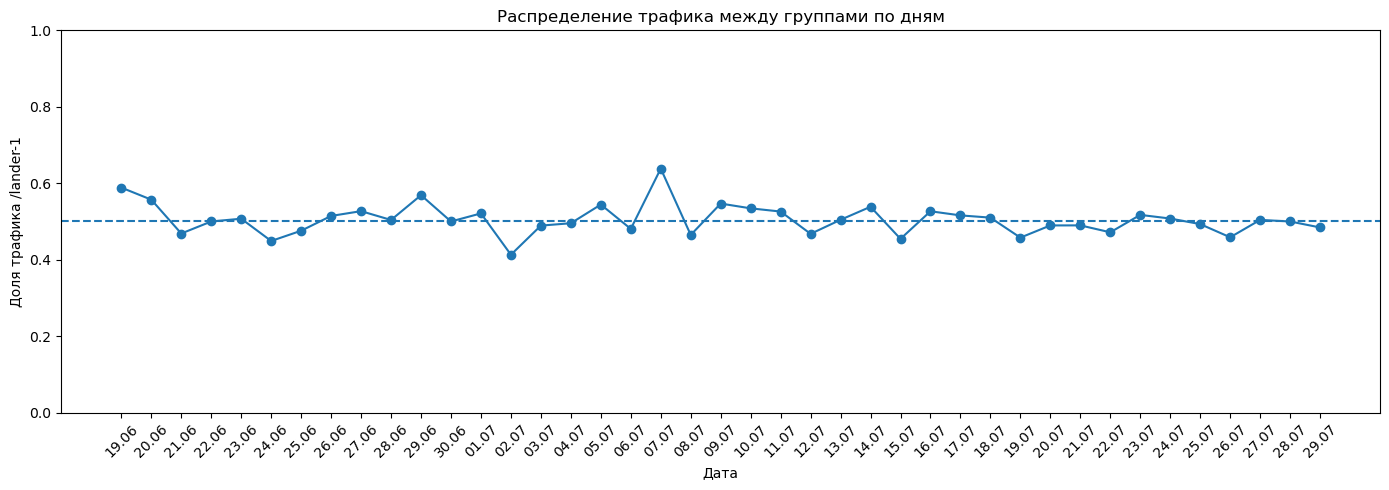

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.plot(
    daily_counts.index,
    daily_counts['treatment_share'],
    marker='o'
)

plt.axhline(
    y=0.5,
    linestyle='--'
)

plt.ylim(0, 1)

plt.xticks(
    ticks=daily_counts.index,
    labels=[date.strftime('%d.%m') for date in daily_counts.index],
    rotation=45
)

plt.xlabel('Дата')
plt.ylabel('Доля трафика /lander-1')
plt.title('Распределение трафика между группами по дням')

plt.tight_layout()
plt.show()

In [11]:
print('Доли трафика, приходящиеся на экспериментальную лендинговую страницу, в период эксперимента')
print('Максимальная:', max(daily_counts['treatment_share']))
print('Минимальная:', min(daily_counts['treatment_share']))

Доли трафика, приходящиеся на экспериментальную лендинговую страницу, в период эксперимента
Максимальная: 0.6382978723404256
Минимальная: 0.41304347826086957


Видны отдельные отклонения от распределения 50/50 по дням, однако они непродолжительны, не образуют устойчивого тренда и не выходят за рамки диапазона `[0.41, 0.64]`. Например, 07.07 наблюдается заметный локальный пик, однако уже в следующие дни распределение возвращается к значениям, близким к 50/50.

## 2. Анализ метрик

После проведения sanity checks переходим к анализу выбранных метрик.

- **Primary metric** - Bounce rate
- **Secondary metrics** - Conversion to order, Revenue per session
- **Guardrail metric** - Conversion to order

Определения данных метрик приведены в README проекта.

### 2.1 Bounce rate

In [12]:
bounce_rate_control = df[df['landing_page'] == '/home']['bounced'].mean()
bounce_rate_experiment = df[df['landing_page'] == '/lander-1']['bounced'].mean()
diff = bounce_rate_experiment - bounce_rate_control

print('Предтестовый baseline bounce rate для сегмента gsearch / nonbrand: 60.99%.')
print(f'Bounce rate контрольной группы: {bounce_rate_control * 100:.4f}%')
print(f'Bounce rate экспериментальной группы: {bounce_rate_experiment * 100:.4f}%')
print(f'Разница Bounce rate в п.п.: {diff * 100:.4f}')
print(f'Относительное изменение Bounce rate: {(bounce_rate_experiment * 100) / bounce_rate_control - 100:.4f}%')

Предтестовый baseline bounce rate для сегмента gsearch / nonbrand: 60.99%.
Bounce rate контрольной группы: 58.6340%
Bounce rate экспериментальной группы: 53.0029%
Разница Bounce rate в п.п.: -5.6311
Относительное изменение Bounce rate: -9.6038%


 Проверим, является ли наблюдаемое различие статистически значимым.

Bounce rate — бинарная метрика на уровне сессии: каждая сессия либо является bounce-сессией (`bounced = 1`), либо нет (`bounced = 0`). Поэтому сравниваются две независимые доли:

- доля bounce-сессий в контрольной группе `/home`;
- доля bounce-сессий в экспериментальной группе `/lander-1`.

Для проверки используется двухвыборочный z-тест для пропорций.

Проверяются односторонние гипотезы:

- **H₀:** bounce rate новой страницы не ниже bounce rate старой страницы, то есть  
  $p_{new} \ge p_{old}$
- **H₁:** bounce rate новой страницы ниже bounce rate старой страницы, то есть  
  $p_{new} < p_{old}$

Односторонняя альтернатива выбрана потому, что бизнес-вопрос сформулирован именно как проверка улучшения новой страницы: нас интересует снижение bounce rate, а не любое отличие между вариантами.

In [13]:
from statsmodels.stats.proportion import proportions_ztest

# Число bounce-сессий
treatment_bounces = df[df['landing_page'] == '/lander-1']['bounced'].sum()
control_bounces = df[df['landing_page'] == '/home']['bounced'].sum()

# Общее число сессий
treatment_sessions = df[df['landing_page'] == '/lander-1'].shape[0]
control_sessions = df[df['landing_page'] == '/home'].shape[0]

count = [treatment_bounces, control_bounces]
nobs = [treatment_sessions, control_sessions]

z_stat, p_value = proportions_ztest(count=count, nobs=nobs, alternative='smaller')

print(f'z-statistic:{z_stat:.5f}')
print(f'p-value: {p_value:.5f}')

z-statistic:-3.89007
p-value: 0.00005


Посмотрим также 95%-й доверительный интервал для разницы bounce rate между экспериментальной и контрольной группами.

In [14]:
from statsmodels.stats.proportion import confint_proportions_2indep

ci_low, ci_high = confint_proportions_2indep(
    count1=treatment_bounces,
    nobs1=treatment_sessions,
    count2=control_bounces,
    nobs2=control_sessions,
    compare='diff',
    method='wald',
    alpha=0.05
)

print(f'95% доверительный интервал, п.п.: [{ci_low * 100:.4f}, {ci_high * 100:.4f}]')

95% доверительный интервал, п.п.: [-8.4632, -2.7989]


Ретроспективно оценённый MDE при фактическом размере выборки, уровне значимости $\alpha=0.05$ и мощности 80% составляет примерно **3.56 п.п.**

Наблюдаемое снижение bounce rate составляет **5.63 п.п.**: с 58.63% в контрольной группе до 53.00% в экспериментальной.

Односторонний z-тест для двух пропорций дал `p-value = 0.00005`, поэтому при уровне значимости $\alpha=0.05$ нулевая гипотеза отвергается. Есть статистически значимые основания считать, что новая посадочная страница снижает bounce rate.

95%-й доверительный интервал для разницы $p_{new} - p_{old}$ составляет `[-8.46; -2.80]` п.п. и полностью находится ниже нуля. При этом 95%-й доверительный интервал допускает, что истинное снижение может быть меньше 3.56 п.п.: его верхняя граница соответствует снижению примерно на 2.80 п.п.

Поскольку заранее установленный порог бизнес-значимого эффекта для исторического эксперимента нам неизвестен, по одному только bounce rate нельзя определить, является ли наблюдаемое снижение практически значимым для бизнеса.

### 2.2 Conversion to order

После анализа основной метрики проверим guardrail-метрику (а также secondary) — conversion to order.

Снижение bounce rate само по себе ещё не гарантирует улучшения бизнес-результата. Пользователи могут чаще переходить дальше посадочной страницы, но при этом реже совершать заказ. Поэтому важно проверить, не сопровождается ли улучшение bounce rate ухудшением конверсии в заказ.

`is_order` — бинарный признак на уровне сессии:

- `is_order = 1` — в рамках сессии был оформлен заказ;
- `is_order = 0` — заказа не было.

Следовательно, conversion to order представляет собой долю сессий с заказом. 

In [15]:
conversion_to_order_control = df[df['landing_page'] == '/home']['is_order'].mean()
conversion_to_order_experiment = df[df['landing_page'] == '/lander-1']['is_order'].mean()
diff_conv = conversion_to_order_experiment - conversion_to_order_control


print(f'Conversion to order контрольной группы: {conversion_to_order_control * 100:.4f}%')
print(f'Conversion to order экспериментальной группы: {conversion_to_order_experiment * 100:.4f}%')
print(f'Разница Conversion to order в п.п.: {diff_conv * 100:.4f}')
print(f'Относительное изменение Conversion to order: {(conversion_to_order_experiment * 100) / conversion_to_order_control - 100:.4f}%')

Conversion to order контрольной группы: 3.2216%
Conversion to order экспериментальной группы: 4.0319%
Разница Conversion to order в п.п.: 0.8103
Относительное изменение Conversion to order: 25.1508%


Для сравнения контрольной и экспериментальной групп снова используется двухвыборочный z-тест для пропорций. Хотя у нас и выросла конверсия относительно контрольной группы, всё равно необходимо провести проверку и проанализировать доверительный интервал.

Поскольку conversion to order является guardrail-метрикой, нас в первую очередь интересует, не ниже ли конверсия для новой посадочной страницы относительно контрольной.

Проверяются односторонние гипотезы:

- **H₀:** conversion to order новой страницы не ниже conversion to order старой страницы, то есть  
  $p_{new} \ge p_{old}$
- **H₁:** conversion to order новой страницы ниже conversion to order старой страницы, то есть  
  $p_{new} < p_{old}$

Отсутствие статистически значимого снижения не доказывает, что конверсия не ухудшилась на практически значимую величину. Для строгой проверки необходимо заранее определить допустимую границу ухудшения conversion to order. В рамках данного анализа такая граница не задавалась, поэтому guardrail-проверка интерпретируется как поиск статистически значимых признаков ухудшения.

In [16]:
# Число ordered-сессий
treatment_orders = df[df['landing_page'] == '/lander-1']['is_order'].sum()
control_orders = df[df['landing_page'] == '/home']['is_order'].sum()

count = [treatment_orders, control_orders]
nobs = [treatment_sessions, control_sessions]

z_stat, p_value = proportions_ztest(count=count, nobs=nobs, alternative='smaller')

print(f'z-statistic:{z_stat:.5f}')
print(f'p-value: {p_value:.5f}')

z-statistic:1.48606
p-value: 0.93137


In [17]:
ci_low, ci_high = confint_proportions_2indep(
    count1=treatment_orders,
    nobs1=treatment_sessions,
    count2=control_orders,
    nobs2=control_sessions,
    compare='diff',
    method='wald',
    alpha=0.05
)

print(f'95% доверительный интервал, п.п.: [{ci_low * 100:.4f}, {ci_high * 100:.4f}]')

95% доверительный интервал, п.п.: [-0.2569, 1.8774]


Итак, `p-value > 0.05`, поэтому статистически значимых свидетельств снижения conversion to order не обнаружено.

Однако 95%-й доверительный интервал для разницы $p_{new}-p_{old}$ составляет `[-0.2569; 1.8774]` п.п. и включает как 0, так и отрицательные значения. Поэтому полностью исключить снижение conversion to order по имеющимся данным нельзя. Если бы мы знали допустимый порог снижения конверсии в заказ, то смогли бы сделать вывод. Например:
- Если бы заранее было установлено, что допустимое снижение conversion to order составляет не более **0.5 п.п.**, то полученная нижняя граница доверительного интервала -0.2569 п.п. находилась бы выше установленного порога. В таком случае данные позволяли бы считать guardrail-метрику находящейся в допустимых пределах.
- Если бы допустимое снижение составляло только **0.1 п.п.**, то текущих данных было бы недостаточно: нижняя граница доверительного интервала -0.2569 п.п. находится ниже порога. Для более точной оценки потребовался бы больший объём данных, который позволил бы уменьшить стандартную ошибку и получить более узкий доверительный интервал.

Как secondary metric наблюдаемая conversion to order выросла на 0.81 п.п., однако 95%-й доверительный интервал для разницы включает 0, поэтому статистически значимое различие между группами по этой метрике тоже не установлено.

### 2.3 Revenue per session

Переходим к анализу последней выбранной secondary метрики. `revenue` — числовой признак на уровне сессии, равный суммарной выручке по всем заказам, совершённым в рамках этой сессии. Если в сессии не было заказов, значение равно 0.

Следовательно, Revenue per session представляет собой среднее значение признака `revenue`.

In [18]:
revenue_per_session_control = df[df['landing_page'] == '/home']['revenue'].mean()
revenue_per_session_experiment = df[df['landing_page'] == '/lander-1']['revenue'].mean()
diff_rev = revenue_per_session_experiment - revenue_per_session_control


print(f'Revenue per session контрольной группы: {revenue_per_session_control:.4f}')
print(f'Revenue per session экспериментальной группы: {revenue_per_session_experiment:.4f}')
print(f'Разница Revenue per session: {diff_rev:.4f}')
print(f'Относительное изменение Revenue per session: {(revenue_per_session_experiment * 100) / revenue_per_session_control - 100:.4f}%')

Revenue per session контрольной группы: 1.6105
Revenue per session экспериментальной группы: 2.0156
Разница Revenue per session: 0.4051
Относительное изменение Revenue per session: 25.1508%


Для сравнения средних двух независимых выборок без предположения о равенстве дисперсий хорошо подходит двухвыборочный t-тест Уэлша. Однако этот тест требует либо нормальности распределения выборочного среднего, либо большого размера выборки (тогда начинает работать ЦПТ). Однако нужно учитывать, что при сильной асимметрии исходного распределения или наличии выбросов может потребоваться значительно больший размер выборки, чтобы распределение выборочного среднего стало достаточно близким к нормальному. Поэтому перед тем, как выбрать тест, посмотрим на значения, которые принимает признак `revenue`.

In [19]:
revenue_values = df.groupby(['landing_page', 'revenue']).size().reset_index(name='session_count')
revenue_values['session_share_pct'] = (
    revenue_values['session_count']
    / revenue_values.groupby('landing_page')['session_count'].transform('sum')
    * 100
)
revenue_values

,landing_page,revenue,session_count,session_share_pct
0,/home,0.00,2253,96.778351
1,/home,49.99,75,3.221649
2,/lander-1,0.00,2285,95.968081
3,/lander-1,49.99,96,4.031919


Признак `revenue` принимает только два значения: `0.00` и `49.99` USD, поэтому на уровне отдельной сессии выполняется точное соотношение: $revenue = 49.99 \cdot is\_order$.

Так как conversion to order — это среднее значение бинарного признака `is_order`, на уровне группы получаем: $Revenue\ per\ session = 49.99 \cdot Conversion\ to\ order$.

Следовательно, разница Revenue per session между экспериментальной и контрольной группами также является линейным преобразованием разницы conversion to order: $\Delta RPS = 49.99 \cdot (p_{new} - p_{old})$.

Поэтому отдельный статистический тест для Revenue per session проводить не будем: он проверял бы ту же разницу, что и уже выполненный тест для Conversion to order, только выраженную в денежных единицах.

При этом уже полученный доверительный интервал для разницы Conversion to order можно напрямую преобразовать в доверительный интервал для разницы Revenue per session. Если доверительный интервал для $(p_{new} - p_{old})$ равен $[L; U]$, то после умножения всех возможных значений разницы на положительную константу 49.99 соответствующий интервал для Revenue per session будет равен: $[49.99L;\ 49.99U]$. Уровень доверия при таком преобразовании не меняется, поскольку Revenue per session является точной линейной функцией Conversion to order.

В пункте 2.2 был получен 95%-й доверительный интервал для разницы conversion to order: $[-0.2569;\ 1.8774]$ п.п. В долях этот интервал равен: $[-0.002569;\ 0.018774]$. Поэтому 95%-й доверительный интервал для разницы Revenue per session составляет: 

$49.99 \cdot [-0.002569;\ 0.018774] = [-0.1284;\ 0.9385]$ USD на сессию.

Поскольку доверительный интервал включает 0, статистически значимое различие Revenue per session между группами не установлено.

In [20]:
revenue_ci_low = ci_low * 49.99
revenue_ci_high = ci_high * 49.99

print(f'95% доверительный интервал для разницы Revenue per session: [{revenue_ci_low:.4f}; {revenue_ci_high:.4f}] USD')

95% доверительный интервал для разницы Revenue per session: [-0.1284; 0.9385] USD


## 3. Сегментация эффекта по device_type

После анализа общих результатов эксперимента посмотрим, различается ли эффект новой посадочной страницы для разных типов устройств.

В доступной экспериментальной выборке возможности для сегментации ограничены. Признаки `utm_source` и `utm_campaign` использовались при реконструкции экспериментального трафика и одинаковы для всех наблюдений. `utm_content` внутри выбранного сегмента также не меняется. Признак `is_repeat_session` оказался константным и равен 0 для всех сессий эксперимента.

Поэтому единственным доступным признаком, по которому имеет смысл провести сегментацию, остаётся `device_type`.

Ранее проверка показала, что распределение `desktop/mobile` между контрольной и экспериментальной группами статистически значимо не различается. Теперь используем этот признак уже не для проверки баланса групп, а для того, чтобы посмотреть, одинаково ли меняется основная метрика `bounce rate` для пользователей с `desktop` и `mobile`.

Сначала рассчитаем bounce rate контрольной и экспериментальной групп отдельно для каждого типа устройства.

In [21]:
device_effect = df.pivot_table(
    index='device_type',
    columns='landing_page',
    values='bounced',
    aggfunc='mean'
)

device_effect['diff_pp'] = (
    device_effect['/lander-1'] - device_effect['/home']
) * 100

device_effect

landing_page,/home,/lander-1,diff_pp
device_type,,,
desktop,0.552095,0.482759,-6.933651
mobile,0.693950,0.685921,-0.802960


Видно, что и в контрольной, и в экспериментальной группе bounce rate выше для пользователей с мобильных устройств. При этом по точечным оценкам можно предположить, что эффект `/lander-1` относительно `/home` различается между `desktop` и `mobile`. Далее рассчитаем доверительные интервалы отдельно для каждого сегмента.

In [22]:
print('Доверительные интервалы для разницы bounce rate')

for device in ['desktop', 'mobile']:

    device_df = df[df['device_type'] == device]

    treatment = device_df[device_df['landing_page'] == '/lander-1']['bounced']
    control = device_df[device_df['landing_page'] == '/home']['bounced']

    effect = treatment.mean() - control.mean()

    ci_low, ci_high = confint_proportions_2indep(
        count1=treatment.sum(),
        nobs1=len(treatment),
        count2=control.sum(),
        nobs2=len(control),
        compare='diff',
        method='newcomb',
        alpha=0.05
    )
    print(f'для {device}: [{ci_low * 100:.4f}; {ci_high * 100:.4f}]')

Доверительные интервалы для разницы bounce rate
для desktop: [-10.1799; -3.6663]
для mobile: [-6.2166; 4.6132]


Для пользователей `desktop` 95%-й доверительный интервал для разницы bounce rate составляет примерно `[-10.18; -3.67]` п.п. и полностью находится ниже 0. Это указывает на снижение bounce rate для экспериментальной группы.

Для пользователей `mobile` доверительный интервал составляет примерно `[-6.22; 4.61]` п.п. и включает 0. Следовательно, имеющихся данных недостаточно, чтобы установить направление эффекта новой посадочной страницы для мобильных пользователей.

### 3.1 Проверка различия эффекта между `desktop` и `mobile`

Ранее мы получили, что разница bounce rate между `/lander-1` и `/home` различается для двух типов устройств:

- для `desktop` bounce rate снизился примерно на 6.93 п.п.;
- для `mobile` bounce rate снизился примерно на 0.80 п.п.

Однако сами по себе разные значения ещё не доказывают, что эффект новой страницы действительно зависит от типа устройства. Даже если истинный эффект для `desktop` и `mobile` одинаков, в конкретной выборке оценки могут немного отличаться случайным образом.

Поэтому теперь нужно проверить, является ли наблюдаемая разница между эффектами достаточно большой по сравнению со случайной погрешностью этих оценок.

Сначала введём обозначения для неизвестных параметров: 

$ p_{new,d} $ - bounce rate `/lander-1` для `desktop`;

$ p_{old,d} $ - bounce rate `/home` для `desktop`;

$ p_{new,m} $ - bounce rate `/lander-1` для `mobile`;

$ p_{old,m} $ - bounce rate `/home` для `mobile`.

Тогда истинный эффект новой страницы для `desktop` равен: $ \Delta_d = p_{new,d} - p_{old,d}. $

А истинный эффект для `mobile`: $ \Delta_m = p_{new,m} - p_{old,m}. $

Нас интересует, одинаковы ли эти два эффекта. Для этого рассмотрим их разность:
$$D = \Delta_d - \Delta_m. $$

После подстановки:
$$ D = (p_{new,d} - p_{old,d}) - (p_{new,m} - p_{old,m}). $$

Если новая страница влияет на `desktop` и `mobile` одинаково, то $\Delta_d=\Delta_m,$ а значит, $D=0.$ 

Поэтому проверяем гипотезы:
$$ H_0:D=0, $$
$$ H_1:D\ne0. $$

Проблема состоит в том, что параметры генеральной совокупности $p_{new,d},  p_{old,d},  p_{new,m}$ и $p_{old,m}$ нам неизвестны. У нас есть только экспериментальная выборка.

Поэтому вместо истинных вероятностей мы рассчитываем их выборочные оценки:

$$
\hat p_{new,d},\quad
\hat p_{old,d},\quad
\hat p_{new,m},\quad
\hat p_{old,m}.
$$

В нашем датасете `bounced` принимает только значения 0 и 1, поэтому среднее значение этого признака в группе как раз равно доле сессий с отказом. По этим значениям рассчитываем выборочные оценки эффектов и оценку интересующей нас разности эффектов:
$$ \hat\Delta_d = \hat p_{new,d}-\hat p_{old,d},\quad
\hat\Delta_m = \hat p_{new,m}-\hat p_{old,m}.$$
$$ \hat D = \hat\Delta_d-\hat\Delta_m. $$

In [23]:
import numpy as np
from scipy.stats import norm

new_desktop = df[
    (df['landing_page'] == '/lander-1') &
    (df['device_type'] == 'desktop')
]['bounced']

old_desktop = df[
    (df['landing_page'] == '/home') &
    (df['device_type'] == 'desktop')
]['bounced']

new_mobile = df[
    (df['landing_page'] == '/lander-1') &
    (df['device_type'] == 'mobile')
]['bounced']

old_mobile = df[
    (df['landing_page'] == '/home') &
    (df['device_type'] == 'mobile')
]['bounced']


# Bounce rate в каждой группе
p_new_d = new_desktop.mean()
p_old_d = old_desktop.mean()

p_new_m = new_mobile.mean()
p_old_m = old_mobile.mean()

# Эффект внутри каждого типа устройства
effect_desktop = p_new_d - p_old_d
effect_mobile = p_new_m - p_old_m


# Разность эффектов
effect_diff = effect_desktop - effect_mobile

Теперь нужно понять, насколько точно по выборке оценена величина $\hat D$. Для этого найдём её стандартную ошибку.

Начнём с одной группы. Признак `bounced` принимает значения 0 и 1, поэтому его можно рассматривать как Bernoulli случайную величину с вероятностью bounced сессии $p$.

Для такой величины дисперсия равна

$$
Var(X)=p(1-p).
$$

Bounce rate в выборке — это среднее значение `bounced` по $n$ сессиям:

$$
\hat p=\frac{X_1+\ldots+X_n}{n}.
$$

Используя стандартные свойства дисперсии и предположение о том, что случайные величины iid, получаем:

$$
Var(\hat p)=\frac{p(1-p)}{n}.
$$

Истинное значение $p$ неизвестно, поэтому при расчётах вместо него используется полученная по выборке оценка $\hat p$:

$$
\widehat{Var}(\hat p)
=
\frac{\hat p(1-\hat p)}{n}.
$$

Именно отсюда в коде появляются выражения вида

```python
p_new_d * (1 - p_new_d) / len(new_desktop) 
```

Здесь `p_new_d` — это $\hat p_{new,d}$, а `len(new_desktop)` — количество наблюдений $n_{new,d}$ в соответствующей группе. Аналогично устроены остальные три слагаемых. Теперь вернёмся к величине, которую мы действительно хотим исследовать:

$$ \hat D = (\hat p_{new,d}-\hat p_{old,d}) - (\hat p_{new,m}-\hat p_{old,m}) = $$
$$ = \hat p_{new,d} - \hat p_{old,d} - \hat p_{new,m} + \hat p_{old,m}.$$

То есть $\hat D$ складывается из четырёх выборочных долей, каждая из этих долей рассчитана по своей группе сессий:

- `/lander-1`, `desktop`;
- `/home`, `desktop`;
- `/lander-1`, `mobile`;
- `/home`, `mobile`.

Эти группы не пересекаются, поэтому соответствующие оценки долей можно считать независимыми. 

Нам нужно понять, насколько сильно значение $\hat D$ может случайно меняться от одной выборки к другой. Для этого найдём стандартную ошибку $\hat D$. Дисперсия $\hat D$ равна сумме дисперсий всех четырёх выборочных долей по независимости групп и свойствам дисперсии:

$$Var(\hat D) = Var(\hat p_{new,d}) + Var(\hat p_{old,d}) + Var(\hat p_{new,m}) + Var(\hat p_{old,m}).$$

Подставим полученную ранее формулу для каждой из четырёх групп:

$$
\widehat{Var}(\hat D)
=
\frac{\hat p_{new,d}(1-\hat p_{new,d})}{n_{new,d}}
+
\frac{\hat p_{old,d}(1-\hat p_{old,d})}{n_{old,d}}
+
\frac{\hat p_{new,m}(1-\hat p_{new,m})}{n_{new,m}}
+
\frac{\hat p_{old,m}(1-\hat p_{old,m})}{n_{old,m}}.
$$

Берём квадратный корень из дисперсии и получаем стандартную ошибку.

In [24]:
se = np.sqrt(
    p_new_d * (1 - p_new_d) / len(new_desktop)
    + p_old_d * (1 - p_old_d) / len(old_desktop)
    + p_new_m * (1 - p_new_m) / len(new_mobile)
    + p_old_m * (1 - p_old_m) / len(old_mobile)
)

Теперь проверим, отличается ли наблюдаемая разность эффектов $\hat D$ от нуля статистически значимо.

По нулевой гипотезе предполагается, что истинная разность эффектов равна нулю. Мы уже получили выборочную оценку $\hat D$ и её стандартную ошибку $SE(\hat D)$. Чтобы понять, насколько далеко наблюдаемое значение $\hat D$ находится от нуля относительно своей случайной изменчивости, стандартизируем эту разность:

$$ z = \frac{\hat D-0}{SE(\hat D)} = \frac{\hat D}{SE(\hat D)}. $$

Полученная $z$-статистика показывает, на сколько стандартных ошибок наблюдаемая разность эффектов удалена от нуля. При достаточно больших объёмах выборок распределение $\hat D$ можно приближённо считать нормальным. Поэтому при выполнении $H_0$ статистика $z$ имеет приближённо стандартное нормальное распределение: $ Z\sim N(0,1).$

Далее рассчитываем `p-value`. Альтернативная гипотеза у нас двусторонняя, поскольку нас интересует любое различие эффекта между `desktop` и `mobile`, независимо от направления. Сначала берём модуль наблюдаемой $z$-статистики. Это нужно потому, что значения $z=3$ и $z=-3$ одинаково далеко находятся от нуля и дают одинаково сильные основания против $H_0$. Функция `norm.sf(abs(z_stat))` вычисляет вероятность получить значение стандартной нормальной случайной величины не меньше наблюдаемого $|z|$. Это вероятность только для положительного хвоста распределения. Так как тест двусторонний, учитываем такое же отклонение и в отрицательную сторону.

Дополнительно построим 95%-й доверительный интервал для истинной разности эффектов $D$. Для двустороннего 95%-го доверительного интервала за его пределами остаётся 5% вероятности, то есть по 2.5% в каждом хвосте нормального распределения: $\frac{1-0.95}{2}=0.025.$ Поэтому нам нужен квантиль стандартного нормального распределения, для которого накопленная вероятность равна `0.975`. Получаем критическое значение $z_{0.975}\approx1.96.$

Тогда 95%-й доверительный интервал для $D$ строится вокруг выборочной оценки $\hat D$:
$$ \hat D \pm 1.96\cdot SE(\hat D). $$ Все расчёты выполняются в долях, поэтому при выводе доверительного интервала его границы умножаются на 100, чтобы представить результат в процентных пунктах.

In [25]:
z_stat = effect_diff / se
p_value = 2 * norm.sf(abs(z_stat))

# 95% доверительный интервал для разности эффектов
z_critical = norm.ppf(0.975)

ci_low = effect_diff - z_critical * se
ci_high = effect_diff + z_critical * se

print('z-statistic:', z_stat)
print('p-value:', p_value)
print(f'95% ДИ для разности эффектов, п.п.: [{ci_low*100:.4f}, {ci_high*100:.4f}]')

z-statistic: -1.897878261733317
p-value: 0.057712120583895486
95% ДИ для разности эффектов, п.п.: [-12.4619, 0.2006]


Итак, `p-value > 0.05` и доверительный интервал содержит 0, а значит, нет оснований отвергнуть $H_0$. Несмотря на то, что в выборке наблюдаются заметные различия в эффекте новой посадочной страницы для пользователей с разными типами устройств, имеющихся данных недостаточно, чтобы статистически подтвердить различие эффектов между `desktop` и `mobile`.

При этом доверительный интервал достаточно широкий. Для более точной оценки различия эффектов и получения более узкого доверительного интервала потребуется больший объём данных.

## 4. Вывод

Проведённые проверки не выявили статистически значимых отклонений в распределении трафика между группами и по типам устройств. Есть статистические основания полагать, что **основная метрика - bounce rate - снизилась** для новой посадочной страницы `/lander-1` относительно `/home`. Наблюдаемое снижение составляет 5.63 п.п., а 95%-й доверительный интервал для разницы между экспериментальной и контрольной группами - `[-8.46; -2.80]` п.п. Однако мы не знаем, какой порог бизнес-значимого изменения основной метрики был установлен для исторического эксперимента. Поэтому можем утверждать о статистической значимости снижения bounce rate, но не о доказанной бизнес-значимости этого изменения.

**Conversion to order** одновременно является guardrail- и secondary-метрикой. Наблюдаемая конверсия в экспериментальной группе выше на 0.81 п.п., однако её 95%-й доверительный интервал для разницы составляет `[-0.2569; 1.8774]` п.п. и включает как 0, так и отрицательные значения. Таким образом, статистически значимого снижения конверсии не обнаружено, но полностью исключить его по имеющимся данным нельзя. Для более точной оценки эффекта потребуется больший объём выборки. Кроме того, для окончательного вывода по guardrail-метрике необходимо знать заранее установленный допустимый порог её снижения.

При анализе **Revenue per session** было обнаружено, что признак `revenue` в рассматриваемой выборке принимает только два значения: `0.00` и `49.99` USD. Поэтому выручка каждой сессии линейно зависит от признака `is_order`:

$$ revenue = 49.99\cdot is\_order. $$

Следовательно, на уровне группы:

$$ Revenue\ per\ session = 49.99\cdot Conversion\ to\ order. $$

Таким образом, отдельный статистический тест для Revenue per session проводить не требуется. Можно воспользоваться уже полученным доверительным интервалом для разницы conversion to order, переведя его из процентных пунктов в доли и умножив границы на 49.99: $ CI_{\Delta RPS} = 49.99\cdot[-0.002569;\ 0.018774] = [-0.1284;\ 0.9385] $ USD на сессию.

Из-за точной линейной зависимости от conversion to order вывод о недостаточной точности оценки полностью переносится и на эту secondary-метрику.

В пункте 3 мы рассмотрели изменение основной метрики в зависимости от типа устройства. По точечным оценкам снижение bounce rate для `desktop` оказалось заметно сильнее, чем для `mobile`: 6.93 п.п. против 0.80 п.п. Однако проверка различия этих эффектов дала `p-value ≈ 0.0577`, а 95%-й доверительный интервал для разности эффектов составил `[-12.46; 0.20]` п.п. Таким образом, мы снова пришли к выводу о недостаточности данных для статистического подтверждения того, что новая посадочная страница по-разному влияет на пользователей с разными типами устройств.

В нескольких частях работы после вычислений мы приходим к выводу, что данных недостаточно для уверенного заключения. Это не ошибка анализа и не означает, что эксперимент оказался бесполезным. Основная метрика продемонстрировала статистически значимое улучшение, однако для вторичных метрик и различий эффектов между сегментами неопределённость остаётся.

Важно учитывать, что мне недоступна информация об исходном дизайне A/B-теста. В рамках анализа я самостоятельно выбрала стандартные параметры: уровень значимости $\alpha=0.05$ и мощность 80%. При этом нигде не указано, что аналитики компании использовали именно такие значения.

При увеличении уровня значимости и снижении требуемой мощности для обнаружения заданного эффекта требуется меньший объём выборки. Поэтому нельзя исключать, что при планировании исторического эксперимента использовались другие параметры. Например, при более высоком уровне значимости некоторые наблюдаемые различия могли бы быть признаны статистически значимыми.

Однако такие изменения имеют свои последствия. При увеличении уровня значимости возрастает риск ошибки первого рода - обнаружения эффекта там, где его в действительности нет. При уменьшении мощности возрастает риск ошибки второго рода — необнаружения реально существующего эффекта. При этом уменьшение требуемой мощности само по себе не делает оценки по уже собранным данным точнее. Таким образом, менее строгие параметры могут сократить необходимый объём выборки, но увеличивают соответствующие риски ошибок.

При реконструкции эксперимента я также проверила, как использовались посадочные страницы после окончания выбранного экспериментального периода. Оказалось, что начиная с 30 июля 2012 года (после проведения эксперимента) для сегмента `gsearch/nonbrand` в данных больше не встречаются просмотры старой страницы `/home`. Это согласуется с предположением, что после эксперимента для данного сегмента решили использовать новую посадочную страницу `/lander-1`.

При этом старая страница не была полностью исключена из использования на сайте. Дополнительный SQL-запрос показал, что после той же даты на всём сайте было зафиксировано 122 812 просмотров `/home`, которые, следовательно, относятся к другим сегментам трафика. Это подтверждает, что изменения в исследуемом сегменте не означали автоматические изменения для всего сайта.

Таким образом, последующее использование новой посадочной страницы косвенно свидетельствует в пользу предположения о закреплении нового варианта за сегментом `gsearch/nonbrand`. Однако сам факт принятия такого бизнес-решения и его причины нельзя достоверно установить только по имеющимся данным.

В итоге новая посадочная страница продемонстрировала статистически значимое снижение bounce rate в исследуемом сегменте трафика. При этом признаков статистически значимого ухудшения conversion to order не обнаружено, хотя полностью исключить снижение конверсии имеющаяся выборка не позволяет. Для более определённых выводов о вторичных метриках и различиях эффекта между типами устройств необходимы дополнительные данные, а для оценки бизнес-значимости — информация о заранее установленных критериях успешности эксперимента.